In [1]:
# hail imports

from pprint import pprint
from bokeh.io import output_notebook, show
from bokeh.layouts import gridplot
from bokeh.models import Span
from bokeh.plotting import figure, show, output_file
import pandas as pd
import os, sys, time
import numpy as np
from collections import Counter

import hail as hl
from bokeh.io import output_notebook, show

Loading BokehJS ...

In [2]:
import seaborn as sns
sns.set(rc={'figure.figsize':(11.7,8.27)})
from scipy.cluster.vq import kmeans2
from scipy.stats import binom_test
from scipy.stats import chi2_contingency
import re

In [3]:
os.environ['JAVA_HOME']='/usr/lib/jvm/java-1.8.0-openjdk-amd64'
os.environ['PATH'] = os.environ['PATH'] + f':{os.environ["JAVA_HOME"]}/bin'
os.environ['JAVA_OPTS']='-Xmx128g'

In [4]:
hl.init(idempotent=True, default_reference='GRCh38', spark_conf={"spark.driver.memory": "100g"})
#hl.init(default_reference='GRCh38')
output_notebook()
#hl.stop()

/home/barbitoff/.local/lib/python3.10/site-packages/hail/context.py:352: UserWarning:

Using hl.init with a default_reference argument is deprecated. To set a default reference genome after initializing hail, call `hl.default_reference` with an argument to set the default reference genome.



26/09/27 10:05:52 WARN Utils: Your hostname, biscuit resolves to a loopback address: 127.0.1.1; using 172.16.0.46 instead (on interface enx00e04c210290)
26/09/27 10:05:52 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
26/09/27 10:05:52 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
Running on Apache Spark version 3.3.4
SparkUI available at http://172.16.0.46:4040
Welcome to
     __  __     <>__
    / /_/ /__  __/ /
   / __  / _ `/ / /
  /_/ /_/\_,_/_/_/   version 0.2.130-bea04d9c79b5
LOGGING: writing to /media/DATA/pregloss_project/hail-20260927-1005-0.2.130-bea04d9c79b5.log


Loading BokehJS ...

# Data import and filters

First, we read the VCF file and store the results in a matrix table to speed-up the analysis scheme

### Reading the MatrixTable data and loading phenotypes

Here we will load the .mt back into our environment (after first conversion, we begin with this step) and add phenotypic information using the metadata `.tsv` file

In [6]:
#geno = hl.import_vcf('/media/CERBADATA/vc_proj/all_outputs/joint_vcf/vep/manually_parsed_2_snp_annotated.vcf') 
#geno = hl.read_matrix_table('/media/CERBADATA/vc_proj/ALL_COHORTS.jc.vcf.FILTERED.SELECTED.mt')
#geno = hl.import_vcf('/media/array/rex_proj/combine_output/filtered/annotation/output_vep_v2.vcf') 

# import vcf and write to mt
genovcf = hl.import_vcf('/media/DATA/pregloss_project/ploss_analysis.v3.VEP.Recalibrated.Filtered.vcf').write(
    '/media/DATA/pregloss_project/ploss.v3.mt', overwrite=True) 

print('VCF stored in .mt!')

VCF stored in .mt!


In [67]:
# read mt
geno = hl.read_matrix_table(
    '/media/DATA/pregloss_project/ploss.v3.mt')

print('vcf import DONE')

vcf import DONE


In [68]:
sa = hl.import_table('/media/DATA/pregloss_project/PL_cohort_meta.v3.tsv',
                     key='SAMPLE', missing=['NA', ''], impute=True)

In [69]:
sa.show()

,,,
SAMPLE,FAMILY_MEMBER,FAMILY_ID,TRIO
str,str,str,int32
"""S102""","""fetus""","""PN96PN95""",1
"""S103""","""fetus""","""PN100PN99""",1
"""S104""","""fetus""","""PN106PN105""",1
"""S108""","""fetus""","""PN108PN107""",NA
"""S109""","""father""","""PN10PN9""",1
"""S110""","""fetus""","""PN112PN111""",NA
"""S111""","""fetus""","""PN110PN109""",1
"""S112""","""mother""","""PN10PN9""",1


In [70]:
geno = geno.annotate_cols(meta = sa[geno.s])
geno.describe()

----------------------------------------
Global fields:
    None
----------------------------------------
Column fields:
    's': str
    'meta': struct {
        FAMILY_MEMBER: str, 
        FAMILY_ID: str, 
        TRIO: int32
    }
----------------------------------------
Row fields:
    'locus': locus<GRCh38>
    'alleles': array<str>
    'rsid': str
    'qual': float64
    'filters': set<str>
    'info': struct {
        AC: array<int32>, 
        AF: array<float64>, 
        AN: int32, 
        BaseQRankSum: float64, 
        COSMIC: array<str>, 
        CSQ: array<str>, 
        ClinVar: array<str>, 
        ClinVar_CLNDISDBINCL: array<str>, 
        ClinVar_CLNDN: array<str>, 
        ClinVar_CLNREVSTAT: array<str>, 
        ClinVar_CLNSIG: array<str>, 
        ClinVar_CLNSIGCONF: array<str>, 
        DP: int32, 
        END: int32, 
        ExcessHet: float64, 
        FS: float64, 
        InbreedingCoeff: float64, 
        LOCALAFDB: array<str>, 
        LOCALAFDB_AF_healthy

In [71]:
geno.meta.show()

+--------+--------------------+----------------+-----------+
| s      | meta.FAMILY_MEMBER | meta.FAMILY_ID | meta.TRIO |
+--------+--------------------+----------------+-----------+
| str    | str                | str            |     int32 |
+--------+--------------------+----------------+-----------+
| "S102" | "fetus"            | "PN96PN95"     |         1 |
| "S103" | "fetus"            | "PN100PN99"    |         1 |
| "S104" | "fetus"            | "PN106PN105"   |         1 |
| "S108" | "fetus"            | "PN108PN107"   |        NA |
| "S109" | "father"           | "PN10PN9"      |         1 |
| "S110" | "fetus"            | "PN112PN111"   |        NA |
| "S111" | "fetus"            | "PN110PN109"   |         1 |
| "S112" | "mother"           | "PN10PN9"      |         1 |
| "S113" | "father"           | "PN12PN11"     |         1 |
| "S115" | "fetus"            | "PN114PN113"   |        NA |
+--------+--------------------+----------------+-----------+
showing top 10 rows

In [72]:
smeta = geno.cols().to_pandas()
smeta.head()

,s,meta.FAMILY_MEMBER,meta.FAMILY_ID,meta.TRIO
0,S102,fetus,PN96PN95,1
1,S103,fetus,PN100PN99,1
2,S104,fetus,PN106PN105,1
3,S108,fetus,PN108PN107,<NA>
4,S109,father,PN10PN9,1


In [73]:
smeta[[pd.isna(x) for x in smeta['meta.FAMILY_MEMBER']]]

,s,meta.FAMILY_MEMBER,meta.FAMILY_ID,meta.TRIO


In [74]:
meta_file = pd.read_csv('PL_cohort_meta.v3.tsv', sep='\t')
meta_file.head()

,SAMPLE,FAMILY_MEMBER,FAMILY_ID,TRIO
0,S103,fetus,PN100PN99,1.0
1,S231,father,PN100PN99,1.0
2,S233,mother,PN100PN99,1.0
3,S240,father,PN102PN101,1.0
4,S251,mother,PN102PN101,1.0


In [75]:
len(set(meta_file['SAMPLE']))

225

In [76]:
meta_file[[x not in list(smeta['s']) for x in meta_file['SAMPLE']]]

,SAMPLE,FAMILY_MEMBER,FAMILY_ID,TRIO


In [77]:
Counter(smeta['meta.FAMILY_MEMBER'])

Counter({'fetus': 75, 'father': 75, 'mother': 75})

In [78]:
geno.count()

(246459, 225)

In [79]:
bi = geno.filter_rows(hl.len(geno.alleles) == 2)
bi = bi.annotate_rows(a_index=1, was_split=False)
multi = geno.filter_rows(hl.len(geno.alleles) > 2)
print(multi.count())
split = hl.split_multi_hts(multi)
geno = split.union_rows(bi)

(0, 225)


In [80]:
geno.count()

(246459, 225)

### Sample quality control + split by lab

Here we explore the sample quality metrics (the default set provided by Hail.
Cutoffs for filtering are selected using visual plot inspection

In [81]:
geno = hl.sample_qc(geno)

In [82]:
# qc before filtering: used for filtering  

# sample_qc plots


hethom = hl.plot.histogram(geno.sample_qc.r_het_hom_var, title='Heterozygous / homozygous call ratio before QC filtering', legend=None)
titv = hl.plot.histogram(geno.sample_qc.r_ti_tv, range=(0, 4), title = 'Transitions / transverions ratio before QC filtering')
r_ins_del = hl.plot.histogram(geno.sample_qc.r_insertion_deletion, title='Insertion / deletion ratio before QC filtering',)
qc_sample = hl.plot.histogram(geno.sample_qc.gq_stats.mean, range=(10,70), bins=100, title='Mean Sample GQ before QC filtering', legend='Mean Sample GQ')


hethom.legend.visible=False
titv.legend.visible=False
r_ins_del.legend.visible=False

In [83]:
show(hethom)
show(titv)
show(r_ins_del)
show(qc_sample)

In [84]:
per_sample_count = hl.plot.histogram(geno.sample_qc.n_non_ref, title='Variants per sample')
sample_call_rate = hl.plot.histogram(geno.sample_qc.call_rate, title='Call rate per sample')
show(per_sample_count)
show(sample_call_rate)

In [85]:
sqc_sa = geno.cols()

In [86]:
sqc_sa.filter(sqc_sa.sample_qc.r_het_hom_var < 1.25).show()

+--------+--------------------+----------------+-----------+
| s      | meta.FAMILY_MEMBER | meta.FAMILY_ID | meta.TRIO |
+--------+--------------------+----------------+-----------+
| str    | str                | str            |     int32 |
+--------+--------------------+----------------+-----------+
| "S108" | "fetus"            | "PN108PN107"   |        NA |
+--------+--------------------+----------------+-----------+

+-------------------------+--------------------------+------------------------+
| sample_qc.dp_stats.mean | sample_qc.dp_stats.stdev | sample_qc.dp_stats.min |
+-------------------------+--------------------------+------------------------+
|                 float64 |                  float64 |                float64 |
+-------------------------+--------------------------+------------------------+
|                7.37e+01 |                 6.56e+01 |               0.00e+00 |
+-------------------------+--------------------------+------------------------+

+------------------------+-------------------------+--------------------------+
| sample_qc.dp_stats.max | sample_qc.gq_stats.mean | sample_qc.gq_stats.stdev |
+------------------------+-------------------------+--------------------------+
|                float64 |                 float64 |                  float64 |
+------------------------+-------------------------+--------------------------+
|               2.54e+03 |                9.27e+01 |                 2.01e+01 |
+------------------------+-------------------------+--------------------------+

+------------------------+------------------------+---------------------+
| sample_qc.gq_stats.min | sample_qc.gq_stats.max | sample_qc.call_rate |
+------------------------+------------------------+---------------------+
|                float64 |                float64 |             float64 |
+------------------------+------------------------+---------------------+
|               0.00e+00 |               9.90e+01 |            9.86e-01 |
+------------------------+------------------------+---------------------+

+--------------------+------------------------+----------------------+
| sample_qc.n_called | sample_qc.n_not_called | sample_qc.n_filtered |
+--------------------+------------------------+----------------------+
|              int64 |                  int64 |                int64 |
+--------------------+------------------------+----------------------+
|             242925 |                   3534 |                    0 |
+--------------------+------------------------+----------------------+

+---------------------+-----------------+---------------------+
| sample_qc.n_hom_ref | sample_qc.n_het | sample_qc.n_hom_var |
+---------------------+-----------------+---------------------+
|               int64 |           int64 |               int64 |
+---------------------+-----------------+---------------------+
|              208970 |           16073 |               17882 |
+---------------------+-----------------+---------------------+

+---------------------+-----------------------+-----------------+
| sample_qc.n_non_ref | sample_qc.n_singleton | sample_qc.n_snp |
+---------------------+-----------------------+-----------------+
|               int64 |                 int64 |           int64 |
+---------------------+-----------------------+-----------------+
|               33955 |                    48 |           47412 |
+---------------------+-----------------------+-----------------+

+-----------------------+----------------------+------------------------+
| sample_qc.n_insertion | sample_qc.n_deletion | sample_qc.n_transition |
+-----------------------+----------------------+------------------------+
|                 int64 |                int64 |                  int64 |
+-----------------------+----------------------+------------------------+
|                  1971 |                 2454 |                  33254 |
+-----------------------+----------------------+------------------------+

+-

In [87]:
sqc_sa.filter(sqc_sa.sample_qc.r_het_hom_var > 2.5).show()

+-------+--------------------+----------------+-----------+
| s     | meta.FAMILY_MEMBER | meta.FAMILY_ID | meta.TRIO |
+-------+--------------------+----------------+-----------+
| str   | str                | str            |     int32 |
+-------+--------------------+----------------+-----------+
| "S30" | "fetus"            | "PN38PN37"     |         1 |
| "S49" | "fetus"            | "PN76PN75"     |         1 |
+-------+--------------------+----------------+-----------+

+-------------------------+--------------------------+------------------------+
| sample_qc.dp_stats.mean | sample_qc.dp_stats.stdev | sample_qc.dp_stats.min |
+-------------------------+--------------------------+------------------------+
|                 float64 |                  float64 |                float64 |
+-------------------------+--------------------------+------------------------+
|                1.23e+02 |                 8.14e+01 |               0.00e+00 |
|                1.08e+02 |                 1.05e+02 |               0.00e+00 |
+-------------------------+--------------------------+------------------------+

+------------------------+-------------------------+--------------------------+
| sample_qc.dp_stats.max | sample_qc.gq_stats.mean | sample_qc.gq_stats.stdev |
+------------------------+-------------------------+--------------------------+
|                float64 |                 float64 |                  float64 |
+------------------------+-------------------------+--------------------------+
|               3.12e+03 |                9.52e+01 |                 1.65e+01 |
|               4.82e+03 |                9.47e+01 |                 1.73e+01 |
+------------------------+-------------------------+--------------------------+

+------------------------+------------------------+---------------------+
| sample_qc.gq_stats.min | sample_qc.gq_stats.max | sample_qc.call_rate |
+------------------------+------------------------+---------------------+
|                float64 |                float64 |             float64 |
+------------------------+------------------------+---------------------+
|               0.00e+00 |               9.90e+01 |            9.96e-01 |
|               0.00e+00 |               9.90e+01 |            9.92e-01 |
+------------------------+------------------------+---------------------+

+--------------------+------------------------+----------------------+
| sample_qc.n_called | sample_qc.n_not_called | sample_qc.n_filtered |
+--------------------+------------------------+----------------------+
|              int64 |                  int64 |                int64 |
+--------------------+------------------------+----------------------+
|             245497 |                    962 |                    0 |
|             244582 |                   1877 |                    0 |
+--------------------+------------------------+----------------------+

+---------------------+-----------------+---------------------+
| sample_qc.n_hom_ref | sample_qc.n_het | sample_qc.n_hom_var |
+---------------------+-----------------+---------------------+
|               int64 |           int64 |               int64 |
+---------------------+-----------------+---------------------+
|              200310 |           35218 |                9969 |
|              199983 |           35421 |                9178 |
+---------------------+-----------------+---------------------+

+---------------------+-----------------------+-----------------+
| sample_qc.n_non_ref | sample_qc.n_singleton | sample_qc.n_snp |
+---------------------+-----------------------+-----------------+
|               int64 |                 int64 |           int64 |
+---------------------+-----------------------+-----------------+
|               45187 |                    49 |           50644 |
|               44599 |                    22 |           49397 |
+---------------------+-----------------------+-----------------+

+-----------------------+--------

In [67]:
geno_flt = geno.filter_cols(geno.sample_qc.r_het_hom_var < 1.25, keep=False)
geno_flt = geno_flt.filter_cols(geno_flt.sample_qc.r_het_hom_var > 2.5, keep=False)
#geno_flt = geno_flt.filter_cols(geno_flt.sample_qc.r_ti_tv < 2.35, keep=False)
#geno_flt = geno_flt.filter_cols(geno_flt.sample_qc.r_ti_tv > 2.75, keep=False)
#geno_flt = geno_flt.filter_cols(geno_flt.sample_qc.r_insertion_deletion > 0.95, keep=False)
#geno_flt = geno_flt.filter_cols(geno_flt.sample_qc.r_insertion_deletion < 0.7, keep=False)
##geno_flt = geno_flt.filter_cols(geno_flt.sample_qc.gq_stats.mean < 30, keep=False)
#geno_flt = geno_flt.filter_cols(geno_flt.sample_qc.call_rate < 0.2, keep=False)
#geno_flt = geno_flt.filter_cols(geno_flt.meta.pct_10x < 0.7, keep=False)

In [68]:
geno_flt.write('/media/DATA/pregloss_project/ploss.v3.sample_qc.mt', overwrite=True) 

In [69]:
geno_flt = hl.read_matrix_table('/media/DATA/pregloss_project/ploss.v3.sample_qc.mt',)
geno_flt.count()

(246459, 222)

In [70]:
# Samlpe QC after filtering

hethom_after = hl.plot.histogram(geno_flt.sample_qc.r_het_hom_var, title='Heterozygous / homozygous call ratio after QC filtering', legend=None)
titv_after = hl.plot.histogram(geno_flt.sample_qc.r_ti_tv, title = 'Transitions / transverions ratio after QC filtering')
r_ins_del_after = hl.plot.histogram(geno_flt.sample_qc.r_insertion_deletion, title='Insertion / deletion ratio after QC filtering',)
gq_after = hl.plot.histogram(geno_flt.sample_qc.gq_stats.mean, range=(10,70), bins=100, title='Mean Sample GQ after QC filtering', legend='Mean Sample GQ')


hethom_after.legend.visible=False
titv_after.legend.visible=False
r_ins_del_after.legend.visible=False

In [71]:
show(hethom_after)
show(titv_after)
show(r_ins_del_after)
show(gq_after)

### Variant quality control and filtering

Here we filter variant siets based on both GATK-provided qualiy stats (as shown in the INFO field of the VCF file) and using the Hail's variant QC module.
Similarly to other analyese, variants are filtered using cutoffs that are selected by visual plot inspection.

In [72]:
# variant qc

geno_flt = hl.variant_qc(geno_flt)

In [73]:
bad_filters = hl.set(['VQSRTrancheINDEL99.30to99.40', 'VQSRTrancheINDEL99.40to99.50', 'VQSRTrancheINDEL99.50to99.60',
              'VQSRTrancheINDEL99.60to99.80', 'VQSRTrancheINDEL99.80to99.90', 'VQSRTrancheINDEL99.90to99.95',
              'VQSRTrancheINDEL99.95to100.00', 'VQSRTrancheSNP99.60to99.80', 'VQSRTrancheSNP99.80to99.90', 
              'VQSRTrancheSNP99.90to99.95', 'VQSRTrancheSNP99.95to100.00'])

In [74]:
#geno_flt = geno_flt.filter_rows(geno_flt.variant_qc.p_value_hwe <= 10^(-10), keep = False)
geno_flt = geno_flt.filter_rows(geno_flt.variant_qc.n_non_ref == 0, keep = False)
#geno_flt = geno_flt.filter_rows(hl.len(geno_flt.filters) > 0, keep=False)

In [75]:
geno_flt.count_rows()

246330

In [76]:
# variant qc fields - total plots

CallRate = hl.plot.histogram(geno_flt.variant_qc.call_rate, title= 'Call rate before QC filtering')
AFH = hl.plot.histogram(hl.min(geno_flt.variant_qc.AF), title= 'AF before QC filtering')
Het = hl.plot.histogram(geno_flt.variant_qc.n_het, title= 'Heterozygous calls before QC filtering')
pValueHWE = hl.plot.histogram(geno_flt.variant_qc.p_value_hwe, title='p-value from test of Hardy-Weinberg equilibrium before QC filtering', )


CallRate.legend.visible=False
Het.legend.visible=False
pValueHWE.legend.visible=False

In [77]:
show(CallRate)
show(AFH)
show(Het)
show(pValueHWE)

In [78]:
##### filtering step: variant 

geno_flt = geno_flt.filter_rows(geno_flt.variant_qc.call_rate < 0.9, keep=False)
#geno_flt = geno_flt.filter_rows(hl.min(geno_flt.variant_qc.AF) < 0.05, keep=False)
geno_flt = geno_flt.filter_rows(geno_flt.info.ExcessHet > 54.60, keep=False)
#geno_flt = geno_flt.filter_rows(geno_flt.variant_qc.p_value_hwe < 10^(-10), keep=False)
geno_flt.count()

(228703, 222)

In [79]:
geno_flt.write('/media/DATA/pregloss_project/ploss.v3.final_qc.mt', overwrite=True) 

In [5]:
geno_flt = hl.read_matrix_table('/media/DATA/pregloss_project/ploss.v3.final_qc.mt')
geno_flt.count()

(228703, 222)

# Creating a single table with all variants

In this section, we construct a table of variants that could be subsequently used to identify certain pathogenic variants in the exomes of our alpinists. In this case, the analysis is done only for the 'A' subgroip

In [6]:
ploss_stat = geno_flt.cols().to_pandas()
ploss_stat.head()

,s,meta.FAMILY_MEMBER,meta.FAMILY_ID,meta.TRIO,sample_qc.dp_stats.mean,sample_qc.dp_stats.stdev,sample_qc.dp_stats.min,sample_qc.dp_stats.max,sample_qc.gq_stats.mean,sample_qc.gq_stats.stdev,...,sample_qc.n_singleton,sample_qc.n_snp,sample_qc.n_insertion,sample_qc.n_deletion,sample_qc.n_transition,sample_qc.n_transversion,sample_qc.n_star,sample_qc.r_ti_tv,sample_qc.r_het_hom_var,sample_qc.r_insertion_deletion
0,S102,fetus,PN96PN95,1,94.543271,77.121183,0.0,3247.0,94.455086,17.78091,...,36,47918,1991,2394,33523,14395,0,2.328795,2.226847,0.831662
1,S103,fetus,PN100PN99,1,85.274261,83.107767,0.0,3580.0,94.028524,18.48763,...,41,47873,1996,2339,33751,14122,0,2.389959,2.147772,0.853356
2,S104,fetus,PN106PN105,1,122.528571,134.105954,0.0,3456.0,91.933643,20.485011,...,649,48644,2364,2550,33437,15207,0,2.19879,2.301847,0.927059
3,S109,father,PN10PN9,1,105.174625,94.333995,0.0,3922.0,94.711822,17.483127,...,307,48208,2027,2371,33848,14360,0,2.357103,2.252364,0.854914
4,S110,fetus,PN112PN111,<NA>,60.068223,51.752672,0.0,2200.0,91.723799,20.987837,...,90,46730,2018,2373,33271,13459,0,2.472026,2.106104,0.8504


In [7]:
Counter(ploss_stat['meta.FAMILY_MEMBER'])

Counter({'father': 75, 'mother': 75, 'fetus': 72})

In [8]:
ploss_stat.loc[[pd.isna(x) for x in ploss_stat['meta.FAMILY_MEMBER']]]

,s,meta.FAMILY_MEMBER,meta.FAMILY_ID,meta.TRIO,sample_qc.dp_stats.mean,sample_qc.dp_stats.stdev,sample_qc.dp_stats.min,sample_qc.dp_stats.max,sample_qc.gq_stats.mean,sample_qc.gq_stats.stdev,...,sample_qc.n_singleton,sample_qc.n_snp,sample_qc.n_insertion,sample_qc.n_deletion,sample_qc.n_transition,sample_qc.n_transversion,sample_qc.n_star,sample_qc.r_ti_tv,sample_qc.r_het_hom_var,sample_qc.r_insertion_deletion


In [9]:
new_agg = (geno_flt.group_cols_by(geno_flt.meta.FAMILY_MEMBER).aggregate(
    gt_stats=hl.agg.call_stats(geno_flt.GT, geno_flt.alleles),
    call_rate=hl.agg.fraction(hl.is_defined(geno_flt.GT))))

In [10]:
ploss_df = new_agg.entries().to_pandas()

In [11]:
ploss_df.head()

,locus,alleles,rsid,qual,filters,info.AC,info.AF,info.AN,info.BaseQRankSum,info.COSMIC,...,variant_qc.n_non_ref,variant_qc.het_freq_hwe,variant_qc.p_value_hwe,variant_qc.p_value_excess_het,FAMILY_MEMBER,gt_stats.AC,gt_stats.AF,gt_stats.AN,gt_stats.homozygote_count,call_rate
0,chr1:924533,"[A, G]",<NA>,543591.0,{},[432],[0.96],450,0.882,None,...,222,0.07797,0.650755,0.349245,father,"[8, 142]","[0.05333333333333334, 0.9466666666666667]",150,"[0, 67]",1.0
1,chr1:924533,"[A, G]",<NA>,543591.0,{},[432],[0.96],450,0.882,None,...,222,0.07797,0.650755,0.349245,fetus,"[6, 138]","[0.041666666666666664, 0.9583333333333334]",144,"[0, 66]",1.0
2,chr1:924533,"[A, G]",<NA>,543591.0,{},[432],[0.96],450,0.882,None,...,222,0.07797,0.650755,0.349245,mother,"[4, 146]","[0.02666666666666667, 0.9733333333333334]",150,"[0, 71]",1.0
3,chr1:924648,"[T, A]",<NA>,262.8,{VQSRTrancheSNP99.80to99.90},[2],[0.004505],444,-2.911,None,...,2,0.009112,0.501144,0.498856,father,"[148, 2]","[0.9866666666666667, 0.013333333333333334]",150,"[73, 0]",1.0
4,chr1:924648,"[T, A]",<NA>,262.8,{VQSRTrancheSNP99.80to99.90},[2],[0.004505],444,-2.911,None,...,2,0.009112,0.501144,0.498856,fetus,"[138, 0]","[1.0, 0.0]",138,"[69, 0]",0.958333


In [12]:
af_data = ploss_df.loc[ploss_df['FAMILY_MEMBER'] == 'fetus']
af_data = af_data.drop(['FAMILY_MEMBER', 'call_rate', 'gt_stats.AF', 
                        'gt_stats.AC', 'gt_stats.AN', 'gt_stats.homozygote_count'],
                      axis=1)

def get_total(elem):
    if elem is None:
        return 0
    else:
        return sum(elem[1:])
 
def annotate_df(source_df, factor_var, factor_level, prefix, target_df=af_data):
    dummy = source_df.loc[source_df[factor_var] == factor_level]
    target_df[f'{prefix}_call_rate'] = list(dummy['call_rate'])
    target_df[f'{prefix}_gt_stats.AF'] = list(dummy['gt_stats.AF'])
    target_df[f'{prefix}_gt_stats.n_hom'] = list(dummy['gt_stats.homozygote_count'])
    target_df[f'{prefix}_gt_stats.AC'] = list(dummy['gt_stats.AC'])
    target_df[f'{prefix}_AN'] = list(dummy['gt_stats.AN'])
    target_df[f'{prefix}_AC'] = [get_total(x) for x in target_df[f'{prefix}_gt_stats.AC']]
    target_df[f'{prefix}_AF'] = [get_total(x) for x in target_df[f'{prefix}_gt_stats.AF']]
    target_df[f'{prefix}_n_hom'] = [get_total(x) for x in target_df[f'{prefix}_gt_stats.n_hom']]
    return target_df
 
af_data = annotate_df(ploss_df, 'FAMILY_MEMBER', 'fetus', 'fetus')
af_data = annotate_df(ploss_df, 'FAMILY_MEMBER', 'mother', 'mother')
af_data = annotate_df(ploss_df, 'FAMILY_MEMBER', 'father', 'father')
 
af_data.head()

,locus,alleles,rsid,qual,filters,info.AC,info.AF,info.AN,info.BaseQRankSum,info.COSMIC,...,mother_AF,mother_n_hom,father_call_rate,father_gt_stats.AF,father_gt_stats.n_hom,father_gt_stats.AC,father_AN,father_AC,father_AF,father_n_hom
1,chr1:924533,"[A, G]",<NA>,543591.0,{},[432],[0.96],450,0.882,None,...,0.973333,71,1.0,"[0.05333333333333334, 0.9466666666666667]","[0, 67]","[8, 142]",150,142,0.946667,67
4,chr1:924648,"[T, A]",<NA>,262.8,{VQSRTrancheSNP99.80to99.90},[2],[0.004505],444,-2.911,None,...,0.000000,0,1.0,"[0.9866666666666667, 0.013333333333333334]","[73, 0]","[148, 2]",150,2,0.013333,0
7,chr1:924652,"[T, A]",<NA>,263.76,{VQSRTrancheSNP99.80to99.90},[3],[0.006757],444,-2.582,None,...,0.006667,0,1.0,"[0.9866666666666667, 0.013333333333333334]","[73, 0]","[148, 2]",150,2,0.013333,0
10,chr1:924658,"[T, A]",<NA>,119.68,{VQSRTrancheSNP99.60to99.80},[1],[0.002252],444,-2.303,None,...,0.000000,0,1.0,"[0.9933333333333333, 0.006666666666666667]","[74, 0]","[149, 1]",150,1,0.006667,0
13,chr1:930248,"[G, A]",<NA>,12523.4,{},[6],[0.013],450,-3.053,None,...,0.020000,0,1.0,"[0.9933333333333333, 0.006666666666666667]","[74, 0]","[149, 1]",150,1,0.006667,0


<Axes: xlabel='fetus_AF AF', ylabel='mother_AF AF'>

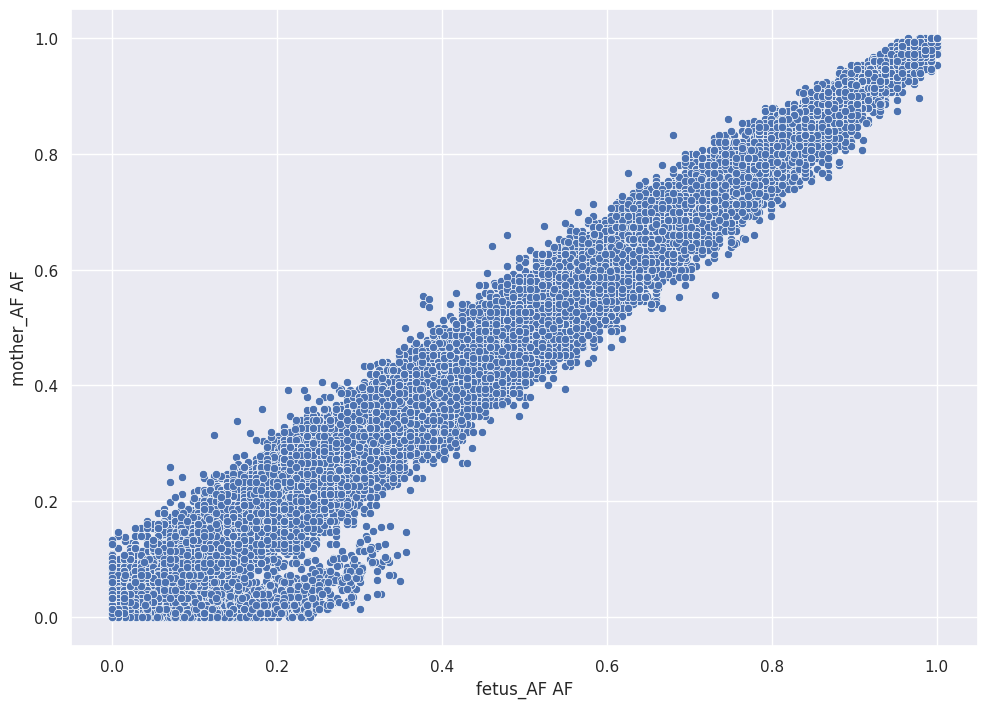

In [13]:
scat_af = sns.scatterplot(af_data, x='fetus_AF', y='mother_AF')
scat_af.set(xlabel='fetus_AF AF', ylabel='mother_AF AF')
scat_af

In [14]:
with open('ploss_analysis.v3.VEP.Recalibrated.Filtered.vcf', 'r') as vcf_handle:
    for line in vcf_handle:
        if line.startswith('##INFO=<ID=CSQ'):
            vep_field_names = line.split('Format: ')[-1].strip('">\n').split('|')
            break
print(vep_field_names)

['Allele', 'Consequence', 'IMPACT', 'SYMBOL', 'Gene', 'Feature_type', 'Feature', 'BIOTYPE', 'EXON', 'INTRON', 'HGVSc', 'HGVSp', 'cDNA_position', 'CDS_position', 'Protein_position', 'Amino_acids', 'Codons', 'Existing_variation', 'DISTANCE', 'STRAND', 'FLAGS', 'SYMBOL_SOURCE', 'HGNC_ID', 'MANE_SELECT', 'MANE_PLUS_CLINICAL', 'REFSEQ_MATCH', 'REFSEQ_OFFSET', 'GIVEN_REF', 'USED_REF', 'BAM_EDIT', 'SOURCE', 'HGVS_OFFSET', 'AF', 'gnomADg_AF', 'gnomADg_AFR_AF', 'gnomADg_AMI_AF', 'gnomADg_AMR_AF', 'gnomADg_ASJ_AF', 'gnomADg_EAS_AF', 'gnomADg_FIN_AF', 'gnomADg_MID_AF', 'gnomADg_NFE_AF', 'gnomADg_OTH_AF', 'gnomADg_SAS_AF', 'MAX_AF', 'MAX_AF_POPS', 'CLIN_SIG', 'SOMATIC', 'PHENO', 'PROVEAN_pred', 'Polyphen2_HVAR_pred', 'SIFT_pred', 'ClinVar', 'ClinVar_CLNSIG', 'ClinVar_CLNSIGCONF', 'ClinVar_CLNREVSTAT', 'ClinVar_CLNDN', 'ClinVar_CLNDISDBINCL', 'LOCALAFDB', 'LOCALAFDB_AF_healthy', 'COSMIC']


In [15]:
def get_vep_field(vep_data_list, field_name, canonical=False, series=False, top_effect=False,
                  vep_field_names=vep_field_names, is_float=False, is_int=False, add_symbol=False):
    vep_dict_list = [dict(zip(vep_field_names, x.split('|'))) for x in vep_data_list]
    if canonical:
        return_dict = {}
        for annotation in vep_dict_list:
            if annotation['CANONICAL'] == 'YES':
                if add_symbol:
                    return_dict[annotation['SYMBOL']] = f'{annotation[field_name]}({annotation["SYMBOL"]})'
                else:
                    return_dict[annotation['SYMBOL']] = annotation[field_name]
        return_value = ';'.join(return_dict.values())
    elif top_effect:
        effect_score = {'MODIFIER': 1, 'LOW': 2, 'MODERATE': 3, 'HIGH': 4}
        scored_values = [(x[field_name], effect_score[x['IMPACT']]) for x in vep_dict_list]
        scored_values.sort(key=lambda x: x[1], reverse=True)
        return_value = scored_values[0][0]
    elif series:
        all_values = set([x[field_name] for x in vep_dict_list])
        return_value = ';'.join(list(all_values))
    else:
        return_value = vep_dict_list[0][field_name]
    if is_float:
        try:
            return float(return_value)
        except:
            return None
    if is_int:
        try:
            return int(return_value)
        except:
            return None
    return return_value

In [16]:
populations = ['gnomADg_AFR_AF', 'gnomADg_AMR_AF', 'gnomADg_EAS_AF', 'gnomADg_SAS_AF', 'gnomADg_NFE_AF',
               'gnomADg_FIN_AF', 'gnomADg_ASJ_AF', 'gnomADg_AF']
for pop_af in populations:
    af_data[pop_af] = [get_vep_field(x, pop_af, is_float=True) for x in af_data['info.CSQ']]
af_data['RUSeq_AF_healthy'] = [get_vep_field(x, 'LOCALAFDB_AF_healthy', is_float=True) for x in af_data['info.CSQ']]
af_data.head()

,locus,alleles,rsid,qual,filters,info.AC,info.AF,info.AN,info.BaseQRankSum,info.COSMIC,...,father_n_hom,gnomADg_AFR_AF,gnomADg_AMR_AF,gnomADg_EAS_AF,gnomADg_SAS_AF,gnomADg_NFE_AF,gnomADg_FIN_AF,gnomADg_ASJ_AF,gnomADg_AF,RUSeq_AF_healthy
1,chr1:924533,"[A, G]",<NA>,543591.0,{},[432],[0.96],450,0.882,None,...,67,0.479500,0.921300,0.688600,0.909800,0.980200,0.961800,0.973200,0.82150,NaN
4,chr1:924648,"[T, A]",<NA>,262.8,{VQSRTrancheSNP99.80to99.90},[2],[0.004505],444,-2.911,None,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,chr1:924652,"[T, A]",<NA>,263.76,{VQSRTrancheSNP99.80to99.90},[3],[0.006757],444,-2.582,None,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10,chr1:924658,"[T, A]",<NA>,119.68,{VQSRTrancheSNP99.60to99.80},[1],[0.002252],444,-2.303,None,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
13,chr1:930248,"[G, A]",<NA>,12523.4,{},[6],[0.013],450,-3.053,None,...,0,0.000868,0.004972,0.000192,0.002275,0.005437,0.002259,0.001728,0.00356,0.005767


In [17]:
Counter([pd.isna(x) for x in af_data['RUSeq_AF_healthy']])

Counter({False: 153157, True: 75546})

<Axes: xlabel='RUSeq healthy AF', ylabel='fetus AF'>

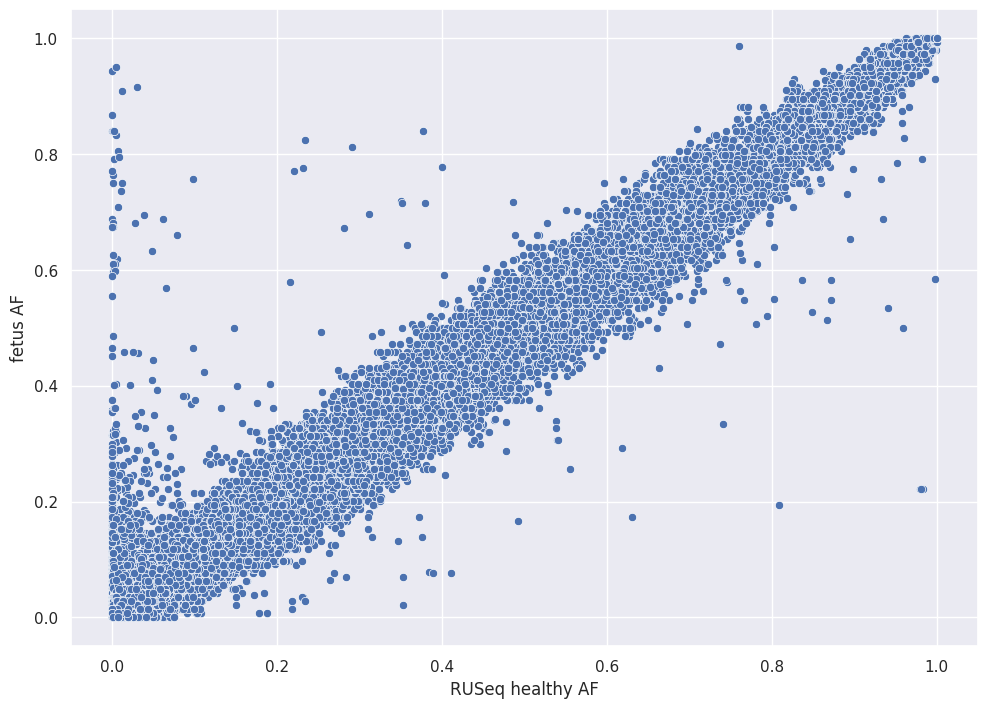

In [18]:
scat_af_ruseq = sns.scatterplot(af_data, x='RUSeq_AF_healthy', y='fetus_AF')
scat_af_ruseq.set(xlabel='RUSeq healthy AF', ylabel='fetus AF')
scat_af_ruseq

In [19]:
af_data['Consequence'] = [get_vep_field(x, 'Consequence', top_effect=True, 
                                        add_symbol=True) for x in af_data['info.CSQ']]
af_data['SYMBOL'] = [get_vep_field(x, 'SYMBOL', series=True) for x in af_data['info.CSQ']]
af_data['Existing_variation'] = [get_vep_field(x, 'Existing_variation') for x in af_data['info.CSQ']]  
#af_data['SIFT'] = [get_vep_field(x, 'SIFT', canonical=True) for x in af_data['info.CSQ']]
#af_data['PolyPhen'] = [get_vep_field(x, 'PolyPhen', canonical=True) for x in af_data['info.CSQ']]
af_data['ClinVar_CLNSIG'] = [get_vep_field(x, 'ClinVar_CLNSIG') for x in af_data['info.CSQ']] 
af_data['ClinVar_CLNDN'] = [get_vep_field(x, 'ClinVar_CLNDN') for x in af_data['info.CSQ']] 
af_data.head()

,locus,alleles,rsid,qual,filters,info.AC,info.AF,info.AN,info.BaseQRankSum,info.COSMIC,...,gnomADg_NFE_AF,gnomADg_FIN_AF,gnomADg_ASJ_AF,gnomADg_AF,RUSeq_AF_healthy,Consequence,SYMBOL,Existing_variation,ClinVar_CLNSIG,ClinVar_CLNDN
1,chr1:924533,"[A, G]",<NA>,543591.0,{},[432],[0.96],450,0.882,None,...,0.980200,0.961800,0.973200,0.82150,NaN,synonymous_variant,LINC02593;SAMD11;LOC284600;LOC107985728,rs112703963,,
4,chr1:924648,"[T, A]",<NA>,262.8,{VQSRTrancheSNP99.80to99.90},[2],[0.004505],444,-2.911,None,...,NaN,NaN,NaN,NaN,NaN,missense_variant,LINC02593;SAMD11;LOC284600;LOC107985728,,,
7,chr1:924652,"[T, A]",<NA>,263.76,{VQSRTrancheSNP99.80to99.90},[3],[0.006757],444,-2.582,None,...,NaN,NaN,NaN,NaN,NaN,missense_variant,LINC02593;SAMD11;LOC284600;LOC107985728,,,
10,chr1:924658,"[T, A]",<NA>,119.68,{VQSRTrancheSNP99.60to99.80},[1],[0.002252],444,-2.303,None,...,NaN,NaN,NaN,NaN,NaN,missense_variant,LINC02593;SAMD11;LOC284600;LOC107985728,,,
13,chr1:930248,"[G, A]",<NA>,12523.4,{},[6],[0.013],450,-3.053,None,...,0.005437,0.002259,0.001728,0.00356,0.005767,missense_variant,SAMD11;LOC107985728,rs41285790,Likely_benign,not_provided


In [20]:
af_data['IMPACT'] = [get_vep_field(x, 'IMPACT', series=True, top_effect=True) for x in af_data['info.CSQ']]
Counter(af_data['IMPACT'])

Counter({'MODERATE': 93005, 'LOW': 76831, 'MODIFIER': 48436, 'HIGH': 10431})

In [21]:
af_data.columns

Index(['locus', 'alleles', 'rsid', 'qual', 'filters', 'info.AC', 'info.AF',
       'info.AN', 'info.BaseQRankSum', 'info.COSMIC', 'info.CSQ',
       'info.ClinVar', 'info.ClinVar_CLNDISDBINCL', 'info.ClinVar_CLNDN',
       'info.ClinVar_CLNREVSTAT', 'info.ClinVar_CLNSIG',
       'info.ClinVar_CLNSIGCONF', 'info.DP', 'info.END', 'info.ExcessHet',
       'info.FS', 'info.InbreedingCoeff', 'info.LOCALAFDB',
       'info.LOCALAFDB_AF_healthy', 'info.MLEAC', 'info.MLEAF', 'info.MQ',
       'info.MQRankSum', 'info.NEGATIVE_TRAIN_SITE',
       'info.POSITIVE_TRAIN_SITE', 'info.QD', 'info.RAW_MQandDP',
       'info.ReadPosRankSum', 'info.SOR', 'info.VQSLOD', 'info.culprit',
       'a_index', 'was_split', 'variant_qc.dp_stats.mean',
       'variant_qc.dp_stats.stdev', 'variant_qc.dp_stats.min',
       'variant_qc.dp_stats.max', 'variant_qc.gq_stats.mean',
       'variant_qc.gq_stats.stdev', 'variant_qc.gq_stats.min',
       'variant_qc.gq_stats.max', 'variant_qc.AC', 'variant_qc.AF',
       'va

In [22]:
Counter([min(x) >= 0.05 for x in af_data['variant_qc.AF']])

Counter({False: 167783, True: 60920})

In [23]:
Counter([min(x) == 1 for x in af_data['variant_qc.AC']])

Counter({False: 172926, True: 55777})

In [24]:
omim = {}
with open('/media/DATA/mountaineers/genes_inheritance.txt', 'r') as omim_file:
    for line in omim_file:
        gene, pattern = line.strip().split('\t')
        omim[gene] = pattern

def add_omim(gene_set, omim_dict=omim):
    pattern_list = []
    for gene in gene_set.split(';'):
        if gene in omim_dict:
            pattern_list.append(omim_dict[gene])
        else:
            pattern_list.append('None')
    return ';'.join(pattern_list)
#    if 'AD' in pattern_list:
#        return 'AD'
#    elif 'AR' in pattern_list:
#        return 'AR'
#    else:
#        return None
        
af_data['inheritance'] = [add_omim(x) for x in af_data['SYMBOL']]
af_data.head()

export_df = af_data.drop('info.CSQ', axis=1, inplace=False)

In [25]:
export_df.to_csv('ploss_data.v3.tsv', sep='\t', index=False)

In [26]:
af_data.to_csv('ploss_data.v3.full.tsv', sep='\t', index=False)

In [27]:
# Beware - allele list has to be carefully handled here!
# Besides, re-imported data do not merge correctly with other DFs due to type mismatch
# af_data = pd.read_csv('ploss_data.full.tsv', sep='\t')
# af_data['alleles'] = [re.findall('[ACGT\*]+', x) for x in af_data['alleles']]

In [28]:
af_data.head()

,locus,alleles,rsid,qual,filters,info.AC,info.AF,info.AN,info.BaseQRankSum,info.COSMIC,...,gnomADg_ASJ_AF,gnomADg_AF,RUSeq_AF_healthy,Consequence,SYMBOL,Existing_variation,ClinVar_CLNSIG,ClinVar_CLNDN,IMPACT,inheritance
1,chr1:924533,"[A, G]",<NA>,543591.0,{},[432],[0.96],450,0.882,None,...,0.973200,0.82150,NaN,synonymous_variant,LINC02593;SAMD11;LOC284600;LOC107985728,rs112703963,,,LOW,None;None;None;None
4,chr1:924648,"[T, A]",<NA>,262.8,{VQSRTrancheSNP99.80to99.90},[2],[0.004505],444,-2.911,None,...,NaN,NaN,NaN,missense_variant,LINC02593;SAMD11;LOC284600;LOC107985728,,,,MODERATE,None;None;None;None
7,chr1:924652,"[T, A]",<NA>,263.76,{VQSRTrancheSNP99.80to99.90},[3],[0.006757],444,-2.582,None,...,NaN,NaN,NaN,missense_variant,LINC02593;SAMD11;LOC284600;LOC107985728,,,,MODERATE,None;None;None;None
10,chr1:924658,"[T, A]",<NA>,119.68,{VQSRTrancheSNP99.60to99.80},[1],[0.002252],444,-2.303,None,...,NaN,NaN,NaN,missense_variant,LINC02593;SAMD11;LOC284600;LOC107985728,,,,MODERATE,None;None;None;None
13,chr1:930248,"[G, A]",<NA>,12523.4,{},[6],[0.013],450,-3.053,None,...,0.001728,0.00356,0.005767,missense_variant,SAMD11;LOC107985728,rs41285790,Likely_benign,not_provided,MODERATE,None;None


In [29]:
af_data.shape

(228703, 99)

### Reading table with population frequencies to be used as priors

In [30]:
ruseq_df = pd.read_csv('/media/DATA/pregloss_project/RUSeqHelathyFreqs.tsv', sep='\t')
ruseq_df.head()

,locus.contig,locus.position,alleles,healthy_AF
0,chr1,13079,"['C', 'G']",0.005000
1,chr1,13086,"['CAG', 'C']",0.000000
2,chr1,13087,"['AG', '*', 'A']",0.000000
3,chr1,13248,"['C', 'G']",0.000870
4,chr1,13273,"['G', 'C']",0.226402


In [31]:
ruseq_df.dtypes

locus.contig       object
locus.position      int64
alleles            object
healthy_AF        float64
dtype: object

In [32]:
ruseq_df['alleles'] = [re.findall('[ACGT\*]+', x) for x in ruseq_df['alleles']]

In [33]:
ruseq_df.head()

,locus.contig,locus.position,alleles,healthy_AF
0,chr1,13079,"[C, G]",0.005000
1,chr1,13086,"[CAG, C]",0.000000
2,chr1,13087,"[AG, *, A]",0.000000
3,chr1,13248,"[C, G]",0.000870
4,chr1,13273,"[G, C]",0.226402


In [34]:
ruseq_df.shape

(2218871, 4)

In [35]:
ruseq_df = ruseq_df.loc[[len(x) == 2 for x in ruseq_df['alleles']]].copy()
ruseq_df.shape

(2089091, 4)

In [36]:
ruseq_df['variant'] = [f'{row[0]}:{row[1]}:{row[2][0]}:{row[2][1]}' for _, row in ruseq_df.iterrows()]
ruseq_df.head()

/tmp/ipykernel_655723/2874731529.py:1: FutureWarning:

Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`



,locus.contig,locus.position,alleles,healthy_AF,variant
0,chr1,13079,"[C, G]",0.005000,chr1:13079:C:G
1,chr1,13086,"[CAG, C]",0.000000,chr1:13086:CAG:C
3,chr1,13248,"[C, G]",0.000870,chr1:13248:C:G
4,chr1,13273,"[G, C]",0.226402,chr1:13273:G:C
5,chr1,13275,"[G, T]",0.000679,chr1:13275:G:T


In [37]:
export_ruseq = ruseq_df[['variant', 'healthy_AF']]
export_ruseq = export_ruseq.rename({'healthy_AF': 'AF'}, axis=1)
export_ruseq.head()

,variant,AF
0,chr1:13079:C:G,0.005000
1,chr1:13086:CAG:C,0.000000
3,chr1:13248:C:G,0.000870
4,chr1:13273:G:C,0.226402
5,chr1:13275:G:T,0.000679


In [128]:
export_ruseq.to_csv('/media/DATA/pregloss_project/RUSeqHelathyFreqs_reformat.tsv', sep='\t')

After preprocessing, we are ready to use the data in Hail for further data analysis

In [38]:
priors = hl.import_table('/media/DATA/pregloss_project/RUSeqHelathyFreqs_reformat.tsv', impute=True)

In [39]:
priors = priors.transmute(**hl.parse_variant(priors.variant)).key_by('locus', 'alleles')

In [40]:
priors.show()

,,,
,AF,locus,alleles
int32,float64,locus<GRCh38>,array<str>
0,5.00e-03,chr1:13079,"[""C"",""G""]"
1,0.00e+00,chr1:13086,"[""CAG"",""C""]"
3,8.70e-04,chr1:13248,"[""C"",""G""]"
4,2.26e-01,chr1:13273,"[""G"",""C""]"
5,6.79e-04,chr1:13275,"[""G"",""T""]"
6,0.00e+00,chr1:13283,"[""C"",""A""]"
7,6.45e-04,chr1:13285,"[""G"",""A""]"
8,8.14e-03,chr1:13289,"[""CCT"",""C""]"


In [41]:
geno_flt_fordenovo = geno_flt.filter_rows(hl.len(geno_flt.filters) > 0, keep=False)

#### Pre-processing meta file to generate pedigree in FAM

In [42]:
meta_df = pd.read_csv('./PL_cohort_meta.v3.tsv', sep='\t')
meta_df.head()

,SAMPLE,FAMILY_MEMBER,FAMILY_ID,TRIO
0,S103,fetus,PN100PN99,1.0
1,S231,father,PN100PN99,1.0
2,S233,mother,PN100PN99,1.0
3,S240,father,PN102PN101,1.0
4,S251,mother,PN102PN101,1.0


In [43]:
meta_df = meta_df.drop_duplicates('SAMPLE')

In [44]:
def get_parent_id(sid, meta_df=meta_df):
    sample_type = meta_df.loc[meta_df['SAMPLE'] == sid, 'FAMILY_MEMBER'].item()
    if  sample_type != 'fetus':
        return ['0', '0']
    fam_id = meta_df.loc[meta_df['SAMPLE'] == sid, 'FAMILY_ID'].item()
    try:
        members = meta_df.loc[meta_df['FAMILY_ID'] == fam_id]
        mat_id = members.loc[members['FAMILY_MEMBER'] == 'mother', 'SAMPLE'].item()
        pat_id = members.loc[members['FAMILY_MEMBER'] == 'father', 'SAMPLE'].item()
        return [mat_id, pat_id]
    except:
        return ['0', '0']

In [45]:
meta_df['MAT_ID'] = [get_parent_id(x)[0] for x in meta_df['SAMPLE']]
meta_df['PAT_ID'] = [get_parent_id(x)[1] for x in meta_df['SAMPLE']]
meta_df.head()

,SAMPLE,FAMILY_MEMBER,FAMILY_ID,TRIO,MAT_ID,PAT_ID
0,S103,fetus,PN100PN99,1.0,S233,S231
1,S231,father,PN100PN99,1.0,0,0
2,S233,mother,PN100PN99,1.0,0,0
3,S240,father,PN102PN101,1.0,0,0
4,S251,mother,PN102PN101,1.0,0,0


In [46]:
sex_codes = {'fetus': 0, 'mother': 2, 'father': 1}
meta_df['SEX'] = [sex_codes[x] for x in meta_df['FAMILY_MEMBER']]
meta_df['PHENO'] = '0'
meta_df.head()

,SAMPLE,FAMILY_MEMBER,FAMILY_ID,TRIO,MAT_ID,PAT_ID,SEX,PHENO
0,S103,fetus,PN100PN99,1.0,S233,S231,0,0
1,S231,father,PN100PN99,1.0,0,0,1,0
2,S233,mother,PN100PN99,1.0,0,0,2,0
3,S240,father,PN102PN101,1.0,0,0,1,0
4,S251,mother,PN102PN101,1.0,0,0,2,0


In [47]:
fam_df = meta_df[['FAMILY_ID', 'SAMPLE', 'PAT_ID', 'MAT_ID', 'SEX', 'PHENO']].copy()
fam_df['FAMILY_ID'] = [x if pd.isna(y) else y for x, y in zip(fam_df['SAMPLE'], fam_df['FAMILY_ID'])]
fam_df.head()

,FAMILY_ID,SAMPLE,PAT_ID,MAT_ID,SEX,PHENO
0,PN100PN99,S103,S231,S233,0,0
1,PN100PN99,S231,0,0,1,0
2,PN100PN99,S233,0,0,2,0
3,PN102PN101,S240,0,0,1,0
4,PN102PN101,S251,0,0,2,0


In [48]:
fam_df.loc[fam_df['PAT_ID'] != '0'].loc[fam_df['MAT_ID'] != '0'].shape

(75, 6)

In [140]:
fam_df.to_csv('/media/DATA/pregloss_project/PL_cohort_meta.v3.fam', header=False, index=False, sep='\t')

In [49]:
pedigree = hl.Pedigree.read('/media/DATA/pregloss_project/PL_cohort_meta.v3.fam')

In [50]:
de_novo_results = hl.de_novo(geno_flt_fordenovo, pedigree, 
                             pop_frequency_prior=priors[geno_flt_fordenovo.row_key].AF)

In [51]:
de_novo_df = de_novo_results.to_pandas()
de_novo_df.head()

,locus,alleles,id,prior,proband.s,proband.meta.FAMILY_MEMBER,proband.meta.FAMILY_ID,proband.meta.TRIO,proband.sample_qc.dp_stats.mean,proband.sample_qc.dp_stats.stdev,...,mother_entry.MIN_DP,mother_entry.PGT,mother_entry.PID,mother_entry.PL,mother_entry.PS,mother_entry.RGQ,mother_entry.SB,is_female,p_de_novo,confidence
0,chr1:965125,"[G, C]",S36,0.315315,S36,fetus,PN34PN33,1,115.125899,80.348249,...,<NA>,None,<NA>,"[0, 120, 1800]",<NA>,<NA>,None,<NA>,0.999953,HIGH
1,chr1:974039,"[C, T]",S36,0.240991,S36,fetus,PN34PN33,1,115.125899,80.348249,...,<NA>,None,<NA>,"[0, 93, 1395]",<NA>,<NA>,None,<NA>,0.990035,HIGH
2,chr1:981210,"[G, A]",S36,0.189189,S36,fetus,PN34PN33,1,115.125899,80.348249,...,<NA>,None,<NA>,"[0, 114, 1710]",<NA>,<NA>,None,<NA>,0.999915,HIGH
3,chr1:1255392,"[G, A]",S36,0.009009,S36,fetus,PN34PN33,1,115.125899,80.348249,...,<NA>,None,<NA>,"[0, 120, 1800]",<NA>,<NA>,None,<NA>,0.999998,HIGH
4,chr1:1628409,"[C, A]",S36,0.312426,S36,fetus,PN34PN33,1,115.125899,80.348249,...,<NA>,None,<NA>,"[0, 120, 1800]",<NA>,<NA>,None,<NA>,0.999953,HIGH


In [52]:
de_novo_df.shape

(3934, 133)

In [53]:
Counter(de_novo_df['confidence'])

Counter({'HIGH': 3380, 'LOW': 392, 'MEDIUM': 162})

In [54]:
list(de_novo_df.columns)

['locus',
 'alleles',
 'id',
 'prior',
 'proband.s',
 'proband.meta.FAMILY_MEMBER',
 'proband.meta.FAMILY_ID',
 'proband.meta.TRIO',
 'proband.sample_qc.dp_stats.mean',
 'proband.sample_qc.dp_stats.stdev',
 'proband.sample_qc.dp_stats.min',
 'proband.sample_qc.dp_stats.max',
 'proband.sample_qc.gq_stats.mean',
 'proband.sample_qc.gq_stats.stdev',
 'proband.sample_qc.gq_stats.min',
 'proband.sample_qc.gq_stats.max',
 'proband.sample_qc.call_rate',
 'proband.sample_qc.n_called',
 'proband.sample_qc.n_not_called',
 'proband.sample_qc.n_filtered',
 'proband.sample_qc.n_hom_ref',
 'proband.sample_qc.n_het',
 'proband.sample_qc.n_hom_var',
 'proband.sample_qc.n_non_ref',
 'proband.sample_qc.n_singleton',
 'proband.sample_qc.n_snp',
 'proband.sample_qc.n_insertion',
 'proband.sample_qc.n_deletion',
 'proband.sample_qc.n_transition',
 'proband.sample_qc.n_transversion',
 'proband.sample_qc.n_star',
 'proband.sample_qc.r_ti_tv',
 'proband.sample_qc.r_het_hom_var',
 'proband.sample_qc.r_insertio

In [55]:
Counter(de_novo_df['proband_entry.GT'])

Counter({Call(alleles=[0, 1], phased=False): 3640,
         Call(alleles=[0, 1], phased=True): 294})

In [56]:
Counter(de_novo_df['mother_entry.GT'])

Counter({Call(alleles=[0, 0], phased=False): 3931,
         Call(alleles=[0, 0], phased=True): 3})

In [57]:
Counter(de_novo_df['father_entry.GT'])

Counter({Call(alleles=[0, 0], phased=False): 3929,
         Call(alleles=[0, 0], phased=True): 5})

In [58]:
de_novo_df.head()

,locus,alleles,id,prior,proband.s,proband.meta.FAMILY_MEMBER,proband.meta.FAMILY_ID,proband.meta.TRIO,proband.sample_qc.dp_stats.mean,proband.sample_qc.dp_stats.stdev,...,mother_entry.MIN_DP,mother_entry.PGT,mother_entry.PID,mother_entry.PL,mother_entry.PS,mother_entry.RGQ,mother_entry.SB,is_female,p_de_novo,confidence
0,chr1:965125,"[G, C]",S36,0.315315,S36,fetus,PN34PN33,1,115.125899,80.348249,...,<NA>,None,<NA>,"[0, 120, 1800]",<NA>,<NA>,None,<NA>,0.999953,HIGH
1,chr1:974039,"[C, T]",S36,0.240991,S36,fetus,PN34PN33,1,115.125899,80.348249,...,<NA>,None,<NA>,"[0, 93, 1395]",<NA>,<NA>,None,<NA>,0.990035,HIGH
2,chr1:981210,"[G, A]",S36,0.189189,S36,fetus,PN34PN33,1,115.125899,80.348249,...,<NA>,None,<NA>,"[0, 114, 1710]",<NA>,<NA>,None,<NA>,0.999915,HIGH
3,chr1:1255392,"[G, A]",S36,0.009009,S36,fetus,PN34PN33,1,115.125899,80.348249,...,<NA>,None,<NA>,"[0, 120, 1800]",<NA>,<NA>,None,<NA>,0.999998,HIGH
4,chr1:1628409,"[C, A]",S36,0.312426,S36,fetus,PN34PN33,1,115.125899,80.348249,...,<NA>,None,<NA>,"[0, 120, 1800]",<NA>,<NA>,None,<NA>,0.999953,HIGH


In [59]:
de_novo_df['locus'][0]

Locus(contig=chr1, position=965125, reference_genome=GRCh38)

In [60]:
de_novo_data = af_data.merge(de_novo_df, on = 'locus', how='inner')
de_novo_data.shape

(4358, 231)

In [61]:
de_novo_data = de_novo_data.loc[[x == y for x, y in zip(de_novo_data['alleles_x'], de_novo_data['alleles_y'])]]
de_novo_data.shape

(3934, 231)

In [62]:
Counter(de_novo_data['IMPACT'])

Counter({'LOW': 1567, 'MODERATE': 1346, 'MODIFIER': 940, 'HIGH': 81})

In [63]:
denovo_counts = Counter(de_novo_data['proband.s'])
denovo_counts

Counter({'S36': 3556,
         'S96': 63,
         'S104': 25,
         'S134': 9,
         'S90': 9,
         'S28': 9,
         'S21': 8,
         'S48': 8,
         'S19': 8,
         'S131': 8,
         'S51': 7,
         'S56': 7,
         'S39': 6,
         'S27': 6,
         'S122': 6,
         'S139': 6,
         'S26': 6,
         'S46': 6,
         'S57': 6,
         'S102': 5,
         'S246': 5,
         'S92': 5,
         'S91': 5,
         'S98': 5,
         'S54': 5,
         'S16': 5,
         'S18': 5,
         'S24': 5,
         'S35': 5,
         'S13': 5,
         'S97': 5,
         'S210': 4,
         'S52': 4,
         'S34': 4,
         'S59': 4,
         'S89': 4,
         'S14': 4,
         'S120': 4,
         'S58': 4,
         'S195': 4,
         'S45': 4,
         'S17': 3,
         'S15': 3,
         'S40': 3,
         'S55': 3,
         'S32': 3,
         'S111': 3,
         'S47': 3,
         'S60': 3,
         'S20': 3,
         'S37': 3,
         'S138'

In [64]:
dnm_counts = pd.DataFrame({'sample_id': denovo_counts.keys(), 'count': denovo_counts.values()})
dnm_counts.head()

,sample_id,count
0,S36,3556
1,S17,3
2,S51,7
3,S15,3
4,S39,6


In [65]:
dnm_counts.to_csv('denovo_stats.v3.tsv', sep='\t', index=False)

In [88]:
sqc_sa.filter(sqc_sa.sample_qc.gq_stats.mean < 69).show()

+--------+--------------------+----------------+-----------+
| s      | meta.FAMILY_MEMBER | meta.FAMILY_ID | meta.TRIO |
+--------+--------------------+----------------+-----------+
| str    | str                | str            |     int32 |
+--------+--------------------+----------------+-----------+
| "S131" | "fetus"            | "PN126PN125"   |        NA |
| "S134" | "fetus"            | "PN128PN127"   |        NA |
| "S139" | "fetus"            | "PN140PN139"   |        NA |
+--------+--------------------+----------------+-----------+

+-------------------------+--------------------------+------------------------+
| sample_qc.dp_stats.mean | sample_qc.dp_stats.stdev | sample_qc.dp_stats.min |
+-------------------------+--------------------------+------------------------+
|                 float64 |                  float64 |                float64 |
+-------------------------+--------------------------+------------------------+
|                8.99e+01 |                 6.25e+01 |               0.00e+00 |
|                6.14e+01 |                 4.25e+01 |               0.00e+00 |
|                9.46e+01 |                 5.94e+01 |               0.00e+00 |
+-------------------------+--------------------------+------------------------+

+------------------------+-------------------------+--------------------------+
| sample_qc.dp_stats.max | sample_qc.gq_stats.mean | sample_qc.gq_stats.stdev |
+------------------------+-------------------------+--------------------------+
|                float64 |                 float64 |                  float64 |
+------------------------+-------------------------+--------------------------+
|               3.05e+03 |                6.49e+01 |                 4.27e+01 |
|               1.72e+03 |                5.58e+01 |                 4.32e+01 |
|               2.79e+03 |                6.78e+01 |                 4.18e+01 |
+------------------------+-------------------------+--------------------------+

+------------------------+------------------------+---------------------+
| sample_qc.gq_stats.min | sample_qc.gq_stats.max | sample_qc.call_rate |
+------------------------+------------------------+---------------------+
|                float64 |                float64 |             float64 |
+------------------------+------------------------+---------------------+
|               0.00e+00 |               9.90e+01 |            9.76e-01 |
|               0.00e+00 |               9.90e+01 |            9.64e-01 |
|               0.00e+00 |               9.90e+01 |            9.74e-01 |
+------------------------+------------------------+---------------------+

+--------------------+------------------------+----------------------+
| sample_qc.n_called | sample_qc.n_not_called | sample_qc.n_filtered |
+--------------------+------------------------+----------------------+
|              int64 |                  int64 |                int64 |
+--------------------+------------------------+----------------------+
|             240479 |                   5980 |                    0 |
|             237512 |                   8947 |                    0 |
|             240103 |                   6356 |                    0 |
+--------------------+------------------------+----------------------+

+---------------------+-----------------+---------------------+
| sample_qc.n_hom_ref | sample_qc.n_het | sample_qc.n_hom_var |
+---------------------+-----------------+---------------------+
|               int64 |           int64 |               int64 |
+---------------------+-----------------+---------------------+
|              203166 |           25169 |               12144 |
|              200195 |           25415 |               11902 |
|              202936 |           24742 |               12425 |
+---------------------+-----------------+---------------------+

+---------------------+-----------------------+-----------------+
| sample_qc.n_non_ref | sample_qc.n_singleton | sample_qc.

In [89]:
de_novo_export = de_novo_data.loc[[x not in ['S36', 'S137', 'S135', 'S96', 'S104'] for x in de_novo_data['proband.s']]]
de_novo_export.shape

(286, 231)

In [90]:
len(set(de_novo_export['proband.s']))

66

In [91]:
de_novo_export.to_csv('ploss_de_novo.v3.tsv', sep='\t', index=False)

In [92]:
de_novo_export.head()

,locus,alleles_x,rsid,qual,filters,info.AC,info.AF,info.AN,info.BaseQRankSum,info.COSMIC,...,mother_entry.MIN_DP,mother_entry.PGT,mother_entry.PID,mother_entry.PL,mother_entry.PS,mother_entry.RGQ,mother_entry.SB,is_female,p_de_novo,confidence
19,chr1:6469122,"[TTCC, T]",<NA>,34778.9,{},[47],[0.104],450,-0.138,None,...,<NA>,None,<NA>,"[0, 109, 1800]",<NA>,<NA>,None,<NA>,0.999737,LOW
29,chr1:10147068,"[A, C]",<NA>,2049.44,{},[1],[0.002222],450,5.18,None,...,<NA>,None,<NA>,"[0, 120, 1800]",<NA>,<NA>,None,<NA>,1.0,HIGH
30,chr1:10158403,"[A, G]",<NA>,2449.44,{},[1],[0.002222],450,6.46,None,...,<NA>,None,<NA>,"[0, 120, 1800]",<NA>,<NA>,None,<NA>,1.0,HIGH
57,chr1:12858964,"[C, T]",<NA>,144939.0,{},[64],[0.143],448,-3.458,None,...,<NA>,None,<NA>,"[0, 120, 1800]",<NA>,<NA>,None,<NA>,0.999972,LOW
121,chr1:40238670,"[A, G]",<NA>,1547.47,{},[1],[0.002222],450,3.29,None,...,<NA>,None,<NA>,"[0, 102, 1255]",<NA>,<NA>,None,<NA>,1.0,HIGH


In [93]:
de_novo_export['SYMBOL']

19      PLEKHG5;TNFRSF25
29                 UBE4B
30                 UBE4B
57               PRAMEF2
121                  RLF
              ...       
4313              ATXN10
4348               CRLF2
4349               CRLF2
4350               CRLF2
4351               CRLF2
Name: SYMBOL, Length: 286, dtype: object

### Trying to get homozygous biallelic genotypes

In [95]:
fetus_list = list(ploss_stat.loc[ploss_stat['meta.FAMILY_MEMBER'] == 'fetus', 's'])

In [96]:
len(fetus_list)

72

In [125]:
biallelic_counts = {}
homozygote_dfs = []
for fetus_id in fetus_list:
    mat_id, pat_id = get_parent_id(fetus_id)
    if mat_id == '0' or pat_id == '0':
#        print(f'Fetus {fetus_id} not a part of a full trio, skipping')
        continue
    biallelic_vars = geno_flt_fordenovo.filter_rows(
        (hl.agg.count_where((geno_flt_fordenovo.s == fetus_id) & geno_flt_fordenovo.GT.is_hom_var()) > 0) &
        (hl.agg.count_where((geno_flt_fordenovo.s == mat_id) & geno_flt_fordenovo.GT.is_het()) > 0) &
        (hl.agg.count_where((geno_flt_fordenovo.s == pat_id) & geno_flt_fordenovo.GT.is_het()) > 0))
    curr_count = biallelic_vars.count_rows()
    biallelic_counts[fetus_id] = curr_count
    biallelic_df = biallelic_vars.rows().to_pandas()
    biallelic_df = biallelic_df.merge(af_data, on='locus', how='inner')
#    print(f'Prior to filtering, there are {len(set(biallelic_df["locus"]))} unique sites')
    biallelic_df = biallelic_df.loc[biallelic_df['alleles_x'] == biallelic_df['alleles_y']].copy()
    biallelic_df = biallelic_df.loc[[x in ['MODERATE', 'HIGH'] for x in biallelic_df['IMPACT']]].copy()
    biallelic_df = biallelic_df.loc[[(x < 0.005) or np.isnan(x) for x in biallelic_df['gnomADg_AF']]].copy()
    curr_flt_count = biallelic_df.shape[0]
    biallelic_df.to_csv(f'{fetus_id}_homozygotized.tsv', sep='\t', index=False)

    # For creation of the combined file
    biallelic_df['ID'] = fetus_id
    homozygote_dfs.append(biallelic_df)
    print(f'Done {fetus_id} with {curr_flt_count}/{curr_count} variants')

Done S102 with 1/1708 variants


Done S103 with 0/1733 variants


Done S104 with 2/1605 variants


Done S110 with 1/1607 variants


Done S111 with 2/1628 variants


Done S115 with 1/1582 variants


Done S120 with 2/1528 variants


Done S121 with 2/1378 variants


Done S122 with 1/1500 variants


Done S129 with 1/1573 variants


Done S13 with 1/1427 variants


Done S130 with 0/1591 variants


Done S131 with 0/1471 variants


Done S132 with 0/1586 variants


Done S133 with 1/1627 variants


Done S134 with 0/1462 variants


Done S135 with 0/1659 variants


Done S136 with 0/1485 variants


Done S137 with 1/1677 variants


Done S138 with 1/1584 variants


Done S139 with 1/1640 variants


Done S14 with 0/1413 variants


Done S15 with 1/1691 variants


Done S16 with 1/1687 variants


Done S17 with 0/1467 variants


Done S18 with 0/1528 variants


Done S19 with 1/1568 variants


Done S193 with 1/1577 variants


Done S194 with 1/1572 variants


Done S195 with 2/1486 variants


Done S20 with 0/1432 variants


Done S21 with 0/1623 variants


Done S210 with 2/1651 variants


Done S24 with 1/1662 variants


Done S246 with 2/1648 variants


Done S26 with 0/1570 variants


Done S27 with 0/1578 variants


Done S28 with 1/1423 variants


Done S29 with 0/1538 variants


Done S31 with 2/1537 variants


Done S32 with 1/1601 variants


Done S33 with 0/1552 variants


Done S34 with 1/1597 variants


Done S35 with 0/1671 variants


Done S36 with 1/1307 variants


Done S37 with 1/1557 variants


Done S39 with 0/1536 variants


Done S40 with 0/1577 variants


Done S44 with 0/1717 variants


Done S45 with 1/1468 variants


Done S46 with 0/1611 variants


Done S47 with 0/1632 variants


Done S48 with 1/1542 variants


Done S50 with 1/1607 variants


Done S51 with 0/1383 variants


Done S52 with 0/1596 variants


Done S53 with 1/1592 variants


Done S54 with 2/1580 variants


Done S55 with 2/1571 variants


Done S56 with 2/1617 variants


Done S57 with 4/1808 variants


Done S58 with 0/1631 variants


Done S59 with 1/1557 variants


Done S60 with 0/1614 variants


Done S89 with 2/1535 variants


Done S90 with 1/1688 variants


Done S91 with 0/1483 variants


Done S92 with 1/1517 variants


Done S93 with 0/1608 variants


Done S96 with 1/1405 variants


Done S97 with 1/1598 variants


Done S98 with 1/1556 variants


In [126]:
all_homo = pd.concat(homozygote_dfs)
all_homo.shape

(59, 158)

In [127]:
all_homo = all_homo[['ID'] + [x for x in list(all_homo.columns) if x != 'ID']]
all_homo.head()

,ID,locus,alleles_x,rsid_x,qual_x,filters_x,info.AC_x,info.AF_x,info.AN_x,info.BaseQRankSum_x,...,gnomADg_ASJ_AF,gnomADg_AF,RUSeq_AF_healthy,Consequence,SYMBOL,Existing_variation,ClinVar_CLNSIG,ClinVar_CLNDN,IMPACT,inheritance
584,S102,chr7:95316772,"[A, T]",<NA>,279447.0,{},[170],[0.379],448,-0.422,...,NaN,NaN,0.353556,missense_variant,PON1,CM971236&COSV55932359,Benign,not_provided&Microvascular_complications_of_di...,MODERATE,None
601,S104,chr6:97182037,"[T, C]",<NA>,2919.13,{},[4],[0.008889],450,4.66,...,0.000000,0.001991,0.001726,missense_variant,MMS22L,rs138515093,,,MODERATE,None
631,S104,chr6:160139865,"[CTGGTAAGT, C]",<NA>,415858.0,{},[262],[0.582],450,0.261,...,NaN,NaN,0.649872,splice_donor_variant&splice_donor_5th_base_var...,SLC22A1,,Benign,not_specified,HIGH,None
109,S110,chr1:215628900,"[C, T]",<NA>,11508.3,{},[7],[0.016],450,-3.298,...,0.000288,0.003648,0.007701,missense_variant,LOC124904778;USH2A,rs111033269&CM140609&COSV100244630,Benign,Usher_syndrome_type_2A&Usher_syndrome&not_prov...,MODERATE,None;AR
941,S111,chr11:71435475,"[C, T]",<NA>,4261.8,{},[4],[0.008889],450,-3.703,...,NaN,NaN,NaN,missense_variant,DHCR7,rs781687341&CM010034,Pathogenic/Likely_pathogenic,not_provided&Smith-Lemli-Opitz_syndrome,MODERATE,AR


<Axes: ylabel='Count'>

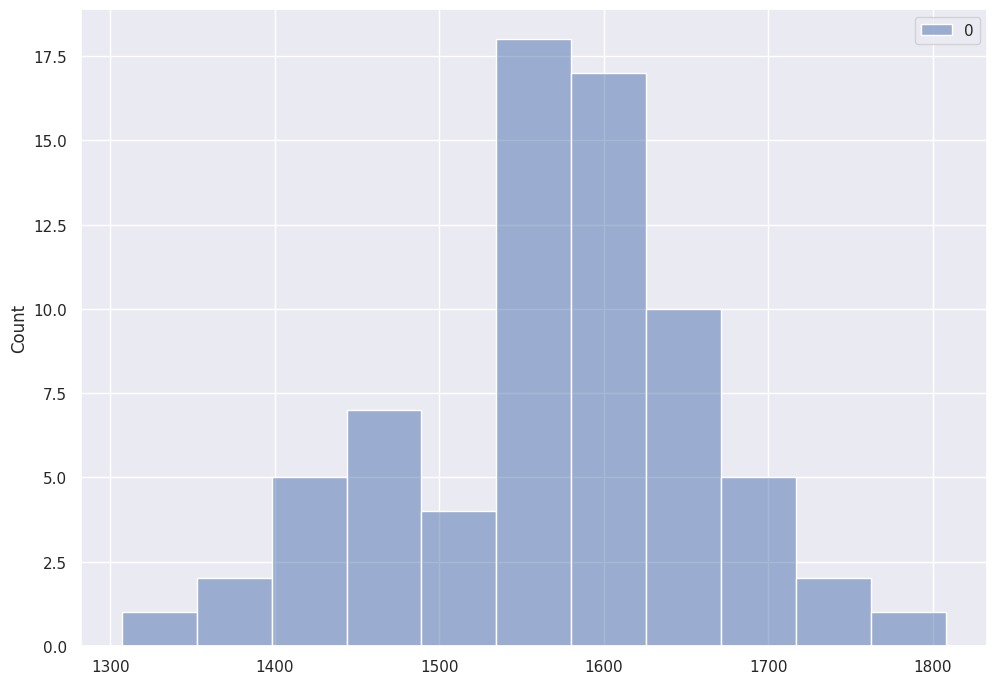

In [128]:
sns.histplot(biallelic_counts.values())

In [129]:
all_homo.to_csv('all_homozygotes.v3.tsv',sep='\t', index=False)

In [130]:
homo_flt_stats = pd.DataFrame(all_homo['ID'].value_counts())
homo_flt_stats.head()

,count
ID,
S57,4
S104,2
S121,2
S111,2
S210,2


In [131]:
homo_flt_stats.to_csv('homozygote_filtered_stats.v3.tsv', sep='\t', index=False)

In [174]:
homo_counts = pd.DataFrame({'sample_id': biallelic_counts.keys(), 'count': biallelic_counts.values()})
homo_counts.head()

,sample_id,count
0,S102,1708
1,S103,1733
2,S104,1605
3,S110,1607
4,S111,1628


In [176]:
homo_counts.to_csv('homozygote_stats.v3.tsv', sep='\t', index=False)

### Attempting detection of candidate compound heterozygotes

Possible algorithm for compound variant detection:
1. Find all variants that are heterozygous in both one parent and fetus;
2. Convert to dfs, filter each DF by impact and frequency;
3. Merge the dataframes by gene to obtain all pairwise combinations;
4. Export the results.

In [107]:
export_cols = ['SYMBOL', 'locus_x', 'alleles_x_x', 'Consequence_x', 'IMPACT_x', 'gnomADg_AF_x', 'RUSeq_AF_healthy_x',
               'Existing_variation_x', 'ClinVar_CLNSIG_x', 'ClinVar_CLNDN_x', 'locus_y', 'alleles_x_y', 
               'Consequence_y', 'IMPACT_y', 'gnomADg_AF_y', 'RUSeq_AF_healthy_y', 'Existing_variation_y',
               'ClinVar_CLNSIG_y', 'ClinVar_CLNDN_y']

compound_candidate_count = {}
compound_dfs = []
compound_withdnm_dfs = []
for fetus_id in fetus_list:
    mat_id, pat_id = get_parent_id(fetus_id)
    if mat_id == '0' or pat_id == '0':
#        print(f'Fetus {fetus_id} not a part of a full trio, skipping')
        continue
    maternal_to_fetal = geno_flt_fordenovo.filter_rows(
        (hl.agg.count_where((geno_flt_fordenovo.s == fetus_id) & geno_flt_fordenovo.GT.is_het()) > 0) &
        (hl.agg.count_where((geno_flt_fordenovo.s == mat_id) & geno_flt_fordenovo.GT.is_het()) > 0))
    paternal_to_fetal = geno_flt_fordenovo.filter_rows(
        (hl.agg.count_where((geno_flt_fordenovo.s == fetus_id) & geno_flt_fordenovo.GT.is_het()) > 0) &
        (hl.agg.count_where((geno_flt_fordenovo.s == pat_id) & geno_flt_fordenovo.GT.is_het()) > 0))
    # Processing first type of variants
    mf_df = maternal_to_fetal.rows().to_pandas()
    mf_df = mf_df.merge(af_data, on='locus', how='inner')
    mf_df = mf_df.loc[mf_df['alleles_x'] == mf_df['alleles_y']].copy()
    mf_df = mf_df.loc[[(x < 0.005) or np.isnan(x) for x in mf_df['gnomADg_AF']]].copy()
    mf_df = mf_df.loc[[x in ['HIGH', 'MODERATE'] for x in mf_df['IMPACT']]]
#    print(mf_df.shape)
    
    pf_df = paternal_to_fetal.rows().to_pandas()
    pf_df = pf_df.merge(af_data, on='locus', how='inner')
    pf_df = pf_df.loc[pf_df['alleles_x'] == pf_df['alleles_y']].copy()
    pf_df = pf_df.loc[[(x < 0.005) or np.isnan(x) for x in pf_df['gnomADg_AF']]].copy()
    pf_df = pf_df.loc[[x in ['HIGH', 'MODERATE'] for x in pf_df['IMPACT']]]
#    print(pf_df.shape)

    pairs_df = mf_df.merge(pf_df, on='SYMBOL', how='inner')
    pairs_df = pairs_df.loc[pairs_df['locus_x'] != pairs_df['locus_y']].copy()

    # Pairs with one DNM
    denovo_sample = de_novo_export.loc[[x == fetus_id for x in de_novo_export['proband.s']]]
    pairs_mat_dnm = mf_df.merge(denovo_sample, on='SYMBOL', how='inner')
    pairs_pat_dnm = pf_df.merge(denovo_sample, on='SYMBOL', how='inner')
    pairs_both_dnm = pd.concat([pairs_mat_dnm, pairs_pat_dnm])
#    print(pairs_both_dnm.shape)
#    break

    # Filtering out combinations present in parents
    mat_vars = set(mf_df['locus'])
    pat_vars = set(pf_df['locus'])
    pairs_df = pairs_df.loc[[(x not in mat_vars) or (y not in mat_vars) for x, y in zip(pairs_df['locus_x'], 
                                                                                        pairs_df['locus_y'])]].copy()
    pairs_df = pairs_df.loc[[(x not in pat_vars) or (y not in pat_vars) for x, y in zip(pairs_df['locus_x'], 
                                                                                        pairs_df['locus_y'])]].copy()
    
    curr_candidates = pairs_df.shape[0]
    curr_candidate_genes = len(set(pairs_df['SYMBOL']))
    candidates_with_dnm = pairs_both_dnm.shape[0]
    compound_candidate_count[fetus_id] = (curr_candidates, curr_candidate_genes, candidates_with_dnm)

    export_pairs = pairs_df[export_cols].copy()
    export_pairs_withdnm = pairs_both_dnm[export_cols].copy()
    
    export_pairs.to_csv(f'{fetus_id}_compounds.tsv', sep='\t', index=False)
    export_pairs_withdnm.to_csv(f'{fetus_id}_compounds_withdnm.tsv', sep='\t', index=False)

    # Assigning IDs
    export_pairs['ID'] = fetus_id
    export_pairs_withdnm['ID'] = fetus_id

    # Combining
    compound_dfs.append(export_pairs)
    compound_withdnm_dfs.append(export_pairs_withdnm)
    
    print(f'Done {fetus_id} with {curr_candidates} candidate compounds in {curr_candidate_genes} genes\nThere are {candidates_with_dnm} compounds with DNMs')

Done S102 with 0 candidate compounds in 0 genes
There are 0 compounds with DNMs


Done S103 with 3 candidate compounds in 3 genes
There are 0 compounds with DNMs


Done S104 with 1 candidate compounds in 1 genes
There are 0 compounds with DNMs


Done S110 with 3 candidate compounds in 3 genes
There are 0 compounds with DNMs


Done S111 with 6 candidate compounds in 6 genes
There are 0 compounds with DNMs


Done S115 with 2 candidate compounds in 2 genes
There are 0 compounds with DNMs


Done S120 with 11 candidate compounds in 1 genes
There are 0 compounds with DNMs


Done S121 with 3 candidate compounds in 3 genes
There are 0 compounds with DNMs


Done S122 with 2 candidate compounds in 2 genes
There are 0 compounds with DNMs


Done S129 with 3 candidate compounds in 2 genes
There are 0 compounds with DNMs


Done S13 with 4 candidate compounds in 3 genes
There are 0 compounds with DNMs


Done S130 with 1 candidate compounds in 1 genes
There are 0 compounds with DNMs


Done S131 with 4 candidate compounds in 4 genes
There are 0 compounds with DNMs


Done S132 with 4 candidate compounds in 3 genes
There are 0 compounds with DNMs


Done S133 with 4 candidate compounds in 4 genes
There are 0 compounds with DNMs


Done S134 with 3 candidate compounds in 3 genes
There are 0 compounds with DNMs


Done S135 with 3 candidate compounds in 3 genes
There are 0 compounds with DNMs


Done S136 with 2 candidate compounds in 2 genes
There are 0 compounds with DNMs


Done S137 with 2 candidate compounds in 2 genes
There are 0 compounds with DNMs


Done S138 with 1 candidate compounds in 1 genes
There are 0 compounds with DNMs


Done S139 with 2 candidate compounds in 2 genes
There are 0 compounds with DNMs


Done S14 with 6 candidate compounds in 5 genes
There are 0 compounds with DNMs


Done S15 with 3 candidate compounds in 3 genes
There are 0 compounds with DNMs


Done S16 with 3 candidate compounds in 3 genes
There are 1 compounds with DNMs


Done S17 with 6 candidate compounds in 3 genes
There are 0 compounds with DNMs


Done S18 with 1 candidate compounds in 1 genes
There are 0 compounds with DNMs


OpenJDK 64-Bit Server VM warning: CodeCache is full. Compiler has been disabled.
OpenJDK 64-Bit Server VM warning: Try increasing the code cache size using -XX:ReservedCodeCacheSize=


CodeCache: size=245760Kb used=244220Kb max_used=244236Kb free=1539Kb
 bounds [0x00007f4a71000000, 0x00007f4a80000000, 0x00007f4a80000000]
 total_blobs=46624 nmethods=45538 adapters=990
 compilation: disabled (not enough contiguous free space left)
Done S19 with 3 candidate compounds in 3 genes
There are 0 compounds with DNMs


Done S193 with 1 candidate compounds in 1 genes
There are 0 compounds with DNMs


Done S194 with 3 candidate compounds in 2 genes
There are 0 compounds with DNMs


Done S195 with 4 candidate compounds in 4 genes
There are 0 compounds with DNMs


Done S20 with 4 candidate compounds in 4 genes
There are 0 compounds with DNMs


Done S21 with 2 candidate compounds in 2 genes
There are 0 compounds with DNMs


Done S210 with 2 candidate compounds in 1 genes
There are 1 compounds with DNMs


Done S24 with 3 candidate compounds in 3 genes
There are 1 compounds with DNMs


Done S246 with 2 candidate compounds in 2 genes
There are 0 compounds with DNMs


Done S26 with 2 candidate compounds in 2 genes
There are 0 compounds with DNMs


Done S27 with 3 candidate compounds in 3 genes
There are 0 compounds with DNMs


Done S28 with 1 candidate compounds in 1 genes
There are 0 compounds with DNMs


Done S29 with 1 candidate compounds in 1 genes
There are 0 compounds with DNMs


Done S31 with 1 candidate compounds in 1 genes
There are 0 compounds with DNMs


Done S32 with 2 candidate compounds in 2 genes
There are 0 compounds with DNMs


Done S33 with 4 candidate compounds in 4 genes
There are 0 compounds with DNMs


Done S34 with 5 candidate compounds in 3 genes
There are 0 compounds with DNMs


Done S35 with 6 candidate compounds in 6 genes
There are 0 compounds with DNMs


Done S36 with 0 candidate compounds in 0 genes
There are 0 compounds with DNMs


Done S37 with 1 candidate compounds in 1 genes
There are 0 compounds with DNMs


Done S39 with 2 candidate compounds in 2 genes
There are 0 compounds with DNMs


Done S40 with 2 candidate compounds in 2 genes
There are 0 compounds with DNMs


Done S44 with 3 candidate compounds in 3 genes
There are 0 compounds with DNMs


Done S45 with 1 candidate compounds in 1 genes
There are 0 compounds with DNMs


Done S46 with 1 candidate compounds in 1 genes
There are 0 compounds with DNMs


Done S47 with 3 candidate compounds in 3 genes
There are 0 compounds with DNMs


Done S48 with 4 candidate compounds in 4 genes
There are 0 compounds with DNMs


Done S50 with 7 candidate compounds in 6 genes
There are 0 compounds with DNMs


Done S51 with 3 candidate compounds in 2 genes
There are 0 compounds with DNMs


Done S52 with 4 candidate compounds in 3 genes
There are 0 compounds with DNMs


Done S53 with 4 candidate compounds in 4 genes
There are 0 compounds with DNMs


Done S54 with 5 candidate compounds in 5 genes
There are 0 compounds with DNMs


Done S55 with 1 candidate compounds in 1 genes
There are 1 compounds with DNMs


Done S56 with 0 candidate compounds in 0 genes
There are 0 compounds with DNMs


Done S57 with 6 candidate compounds in 6 genes
There are 0 compounds with DNMs


Done S58 with 12 candidate compounds in 9 genes
There are 0 compounds with DNMs


Done S59 with 5 candidate compounds in 5 genes
There are 1 compounds with DNMs


Done S60 with 3 candidate compounds in 3 genes
There are 0 compounds with DNMs


Done S89 with 2 candidate compounds in 2 genes
There are 0 compounds with DNMs


Done S90 with 3 candidate compounds in 3 genes
There are 0 compounds with DNMs


Done S91 with 5 candidate compounds in 4 genes
There are 0 compounds with DNMs


Done S92 with 0 candidate compounds in 0 genes
There are 0 compounds with DNMs


Done S93 with 1 candidate compounds in 1 genes
There are 0 compounds with DNMs


Done S96 with 6 candidate compounds in 5 genes
There are 0 compounds with DNMs


Done S97 with 10 candidate compounds in 7 genes
There are 0 compounds with DNMs


Done S98 with 4 candidate compounds in 4 genes
There are 0 compounds with DNMs


In [108]:
all_compound = pd.concat(compound_dfs)
all_compound.shape

(230, 20)

In [109]:
all_compound_withdnm = pd.concat(compound_withdnm_dfs)
all_compound_withdnm.shape

(5, 20)

In [110]:
all_compound = all_compound[['ID'] + [x for x in list(all_compound.columns) if x != 'ID']]
all_compound.head()

,ID,SYMBOL,locus_x,alleles_x_x,Consequence_x,IMPACT_x,gnomADg_AF_x,RUSeq_AF_healthy_x,Existing_variation_x,ClinVar_CLNSIG_x,ClinVar_CLNDN_x,locus_y,alleles_x_y,Consequence_y,IMPACT_y,gnomADg_AF_y,RUSeq_AF_healthy_y,Existing_variation_y,ClinVar_CLNSIG_y,ClinVar_CLNDN_y
0,S103,CROCC,chr1:16954773,"[C, T]",missense_variant,MODERATE,0.000913,0.002415,rs201108592,,,chr1:16955337,"[G, A]",missense_variant,MODERATE,0.000427,0.004202,rs145972878,Uncertain_significance,Inborn_genetic_diseases
1,S103,AKAP9,chr7:92022988,"[G, C]",missense_variant,MODERATE,0.000558,0.007472,rs144372406&COSV62358265,Likely_benign,Cardiovascular_phenotype&not_specified&Long_QT...,chr7:91973828,"[A, G]",missense_variant,MODERATE,NaN,NaN,rs747011533,,
2,S103,TBC1D4,chr13:75312867,"[T, C]",missense_variant,MODERATE,0.003852,0.010986,rs149821147,Benign,not_specified&not_provided,chr13:75362393,"[T, G]",missense_variant,MODERATE,0.000263,0.000593,rs200446215,Conflicting_interpretations_of_pathogenicity,not_specified&Inborn_genetic_diseases
1,S104,CHML;OPN3,chr1:241635737,"[A, G]",missense_variant,MODERATE,0.000243,0.001426,rs3765825&COSV100087354,,,chr1:241634985,"[T, G]",missense_variant,MODERATE,NaN,NaN,rs377486221,,
1,S110,DPYSL3,chr5:147509563,"[G, A]",missense_variant,MODERATE,0.000059,0.000592,rs775105003,,,chr5:147415766,"[T, C]",missense_variant,MODERATE,0.003983,0.015499,rs147541241&CM136041&COSV99063426,,


In [111]:
all_compound.to_csv('all_compound_candidates.v3.tsv',sep='\t', index=False)

Exporting sats of final per-sample compound counts

In [122]:
compound_stats = pd.DataFrame(all_compound['ID'].value_counts())
compound_stats.head()

,count
ID,
S58,12
S120,11
S97,10
S50,7
S57,6


In [123]:
compound_stats.to_csv('compound_stats.v3.tsv', sep='\t', index=False)

In [112]:
all_compound_withdnm = all_compound_withdnm[['ID'] + [x for x in list(all_compound_withdnm.columns) if x != 'ID']]
all_compound_withdnm.head()

,ID,SYMBOL,locus_x,alleles_x_x,Consequence_x,IMPACT_x,gnomADg_AF_x,RUSeq_AF_healthy_x,Existing_variation_x,ClinVar_CLNSIG_x,ClinVar_CLNDN_x,locus_y,alleles_x_y,Consequence_y,IMPACT_y,gnomADg_AF_y,RUSeq_AF_healthy_y,Existing_variation_y,ClinVar_CLNSIG_y,ClinVar_CLNDN_y
0,S16,KCNH2,chr7:150958449,"[G, A]",missense_variant,MODERATE,0.000349,0.003745,rs36210422&CM001198,Conflicting_interpretations_of_pathogenicity&r...,not_provided&Short_QT_syndrome_type_1&not_spec...,chr7:150948446,"[T, A]",missense_variant&splice_region_variant,MODERATE,0.000000,NaN,rs1805123&CM004877&COSV105086818&COSV51125898,Uncertain_significance,Cardiac_arrhythmia&Long_QT_syndrome&not_provided
0,S210,PKP2,chr12:32824092,"[C, T]",missense_variant,MODERATE,0.002405,0.001186,rs146102241&CD106833&CM068257,Conflicting_interpretations_of_pathogenicity,Cardiovascular_phenotype&Ventricular_tachycard...,chr12:32796308,"[G, GA]",splice_polypyrimidine_tract_variant&intron_var...,LOW,0.002260,0.053649,rs746936605,Benign/Likely_benign,Arrhythmogenic_right_ventricular_dysplasia_9&n...
0,S24,VWA8,chr13:41615006,"[C, T]",missense_variant,MODERATE,0.004568,0.003444,rs73464952,,,chr13:41732143,"[T, C]",synonymous_variant,LOW,0.000007,NaN,rs1198518850,,
0,S55,KIFAP3,chr1:169961073,"[C, T]",missense_variant,MODERATE,0.001295,0.001120,rs200944427,,,chr1:170024588,"[A, G]",missense_variant,MODERATE,NaN,NaN,COSV100810961,,
0,S59,UACA,chr15:70666926,"[T, G]",missense_variant,MODERATE,0.000250,0.000572,rs201992560,Uncertain_significance,Inborn_genetic_diseases,chr15:70671017,"[T, TA]",intron_variant,MODIFIER,0.000840,0.007160,rs372164200,,


In [113]:
all_compound_withdnm.to_csv('all_compound_candidates_withdnm.v3.tsv',sep='\t', index=False)